<a href="https://colab.research.google.com/github/tiara-salsabila/pm-turi1/blob/main/pm_turi4_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import numpy as np, pandas as pd
np.random.seed(42)
n_samples = 200

df = pd.DataFrame({
    'usia': np.random.randint(18, 65, size=n_samples),
    'pendapatan': np.random.randint(3, 30, size=n_samples) * 1000000,
    'skor_belanja': np.random.randint(1, 100, size=n_samples)
})

In [17]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)

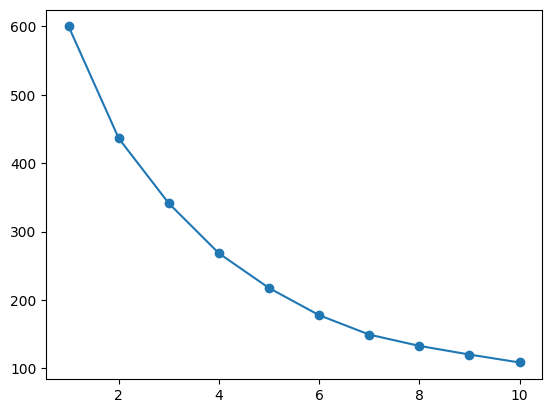

In [18]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

In [19]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
0    70
2    66
1    64
Name: count, dtype: int64


In [20]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.26073876516543165


In [21]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil[cite: 1]

         usia  pendapatan  skor_belanja
cluster                                
0        50.6  23271428.6          49.8
1        47.5   6812500.0          42.9
2        26.3  15515151.5          57.1


In [22]:
# Menjalankan K-Means dengan K=5
kmeans_k5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster_k5'] = kmeans_k5.fit_predict(X_scaled)

# Menghitung dan mencetak silhouette score untuk K=5
score_k5 = silhouette_score(X_scaled, df['cluster_k5'])

# Mendefinisikan variabel score untuk K=3 (sebelumnya) agar tidak terjadi NameError
score = silhouette_score(X_scaled, df['cluster'])

print(f"Silhouette Score (K=5): {score_k5:.3f}")
print(f"Silhouette Score (K=3 sebelumnya): {score:.3f}")

Silhouette Score (K=5): 0.308
Silhouette Score (K=3 sebelumnya): 0.261


In [23]:
# Langsung jalankan K-Means pada df asli (tanpa X_scaled / tanpa scaling)
kmeans_tanpa_scale = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_tanpa_scale = kmeans_tanpa_scale.fit_predict(df[['usia', 'pendapatan', 'skor_belanja']])

# Menghitung silhouette score tanpa scaling
score_tanpa_scale = silhouette_score(df[['usia', 'pendapatan', 'skor_belanja']], cluster_tanpa_scale)
print(f"Silhouette Score (Tanpa Scaling, K=3): {score_tanpa_scale:.3f}")
print(f"Silhouette Score (Dengan Scaling, K=3): {score:.3f}")

Silhouette Score (Tanpa Scaling, K=3): 0.629
Silhouette Score (Dengan Scaling, K=3): 0.261


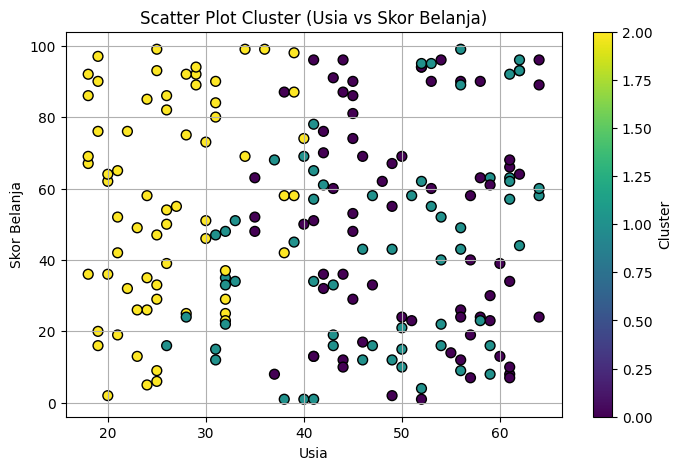

In [24]:
import matplotlib.pyplot as plt

# Membuat scatter plot menggunakan hasil cluster K=3
plt.figure(figsize=(8, 5))
plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=50, edgecolor='k')
plt.title('Scatter Plot Cluster (Usia vs Skor Belanja)')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

1. Bagaimana K-Means menemukan kelompok tanpa label?
K-Means menemukan kelompok tanpa label (unsupervised learning) dengan cara mengelompokkan data berdasarkan kemiripan karakteristik atau jarak terdekat antar titik data ke titik pusat yang ditentukan secara iteratif hingga konvergen

2. Metode Elbow membentuk titik "siku" pada nilai K=3 karena penambahan jumlah klaster setelah angka tersebut tidak lagi memberikan penurunan nilai inertia secara signifikan. Hal ini mengindikasikan bahwa jumlah kelompok yang paling efektif dan optimal untuk data tersebut adalah tiga klaster

3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?
Scaling sangat penting karena algoritma K-Means berbasis perhitungan jarak. Jika dilewatkan fitur dengan rentang nilai yang sangat besar seperti pendapatan yang mencapai jutaan akan mendominasi perhitungan jarak dibandingkan fitur dengan rentang kecil seperti usia atau skor belanja, sehingga hasil pengelompokan menjadi tidak akurat